# 03. 연결 검증

**목적:** 01~02가 만든 상권·업종·분기 격자와 공연·시설 연결을 독립적으로 재계산한다. 두 업종은 연결 검증용 격자이며, 기본 연구 범위인 외식업 10종은 04에서 만든다.

키·범위·매출 결측 보존, 공식/임시 시설 연결, 분기 확장과 공간 거리, 원본 범위와 무결성을 검사한다. 구조 검증 통과와 해석 한계를 분리한다. 검증된 스냅샷만 오프라인으로 읽으며 산출물은 `results/main/baseline/`에 저장한다.

In [1]:
from pathlib import Path
import hashlib, json, platform, unicodedata
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/analysis').is_dir())
A, K, RAW = ROOT / 'data/analysis/final', ROOT / 'data/processed/kopis', ROOT / 'data/raw'
REPORTS = ROOT / 'results/main/baseline'
FIGURES = REPORTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
KEY = ['area_id', 'industry_id', 'quarter']
QUARTERS = [f'{y}{q}' for y in range(2023, 2026) for q in range(1, 5)]
TARGETS = ['종로구', '마포구']
RADII = [300, 500, 800]
EXPOSURES = [f'known_performance_count_{r}m' for r in RADII]
pd.set_option('display.max_rows', 20)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
print('Python:', platform.python_version(), '| 분석 기준: 2023~2025년 분기')

Python: 3.12.14 | 분석 기준: 2023~2025년 분기


## 1. 입력 스키마와 원본 보존

`metadata/main/validation_sources.json`은 월별 목록 XML 전체·변환 관측표·읽기 전용 기준선을 고정한 보조 검증 명세다. 분석 스냅샷과 함께 SHA-256을 확인하고 지정된 XML만 사용한다. 인증 정보가 있을 수 있는 request JSON은 읽지 않는다.

In [2]:
validation_sources = json.loads((ROOT / 'metadata/main/validation_sources.json').read_text(encoding='utf-8'))
for record in validation_sources['files']:
    assert hashlib.sha256((ROOT / record['path']).read_bytes()).hexdigest() == record['sha256'], record['path']
linkage_source = json.loads((REPORTS / 'linkage_analysis_summary.json').read_text(encoding='utf-8'))
source_by_role = {row['role']: row for row in linkage_source['source_files']}
for row in linkage_source['source_files']:
    assert hashlib.sha256((ROOT / row['path']).read_bytes()).hexdigest() == row['sha256']
input_paths = {
    'panel': A / 'performance_sales_panel.csv',
    'sales_panel': A / 'sales_stores_panel.csv',
    'areas': A / 'study_areas.csv',
    'linkage': A / 'performance_facility_linkage.csv',
    'active': A / 'performance_facility_quarter.csv',
    'distances': A / 'venue_area_distances_800m.csv',
    'facilities': ROOT / source_by_role['facilities_list']['path'],
    'performance_list': ROOT / source_by_role['performances_list']['path'],
    'performance_candidates': ROOT / source_by_role['performance_candidates']['path'],
    'facility_details': ROOT / source_by_role['facility_details']['path'],
    'performance_details': ROOT / source_by_role['performance_details']['path'],
    'month_observations': K / 'performance_month_observations_seoul_2023_2025.csv',
}
frames = {name: pd.read_csv(path, dtype={c: str for c in KEY}) for name, path in input_paths.items()}
panel, sales_panel, areas = frames['panel'], frames['sales_panel'], frames['areas']
linkage, active, distances = frames['linkage'], frames['active'], frames['distances']
facilities, details = frames['facilities'], frames['facility_details']
performance_details, month_obs = frames['performance_details'], frames['month_observations']
performance_list, performance_candidates = frames['performance_list'], frames['performance_candidates']
schema = pd.DataFrame([{'dataset': name, 'rows': len(frame), 'columns': frame.shape[1],
                       'column_names': ' | '.join(frame.columns)} for name, frame in frames.items()])
schema.to_csv(REPORTS / '04_input_schema.csv', index=False, encoding='utf-8-sig')
display(schema[['dataset', 'rows', 'columns']])

,dataset,rows,columns
0,panel,3624,35
1,sales_panel,3624,32
2,areas,151,4
3,linkage,30047,20
4,active,31988,4
5,distances,10493,3
6,facilities,1755,7
7,performance_list,30047,10
8,performance_candidates,13727,12
9,facility_details,1755,22


In [3]:
def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

raw_xml = [ROOT / r['path'] for r in validation_sources['files'] if r['role'] == 'monthly_xml']
boundaries = [ROOT / row['path'] for row in linkage_source['source_files'] if row['role'].startswith('boundary_')]
watched_paths = list(input_paths.values()) + raw_xml + boundaries
before_hashes = {str(p.relative_to(ROOT)): sha256(p) for p in watched_paths}
checks = []
def check(name, failed_rows, note=''):
    checks.append({'check': name, 'failed_rows': int(failed_rows),
                   'passed': int(failed_rows) == 0, 'note': note})

print(f'변경 감시 파일 {len(watched_paths)}개: 분석 입력 {len(input_paths)}개, 선택 원본 {len(watched_paths)-len(input_paths)}개')

변경 감시 파일 401개: 분석 입력 12개, 선택 원본 389개


**해석:** CSV 스키마 자체는 데이터의 정확성을 증명하지 않는다. 아래에서는 행을 직접 비교하고 공연 노출을 다시 집계한다. 현재 저장된 상권 경계를 모든 과거 분기에 공통 적용했다는 제약은 구조 검증 통과와 별도로 남는다.

## 2. 패널 키·연구 범위·미제공 매출

151개라는 기존 요약값을 전제하지 않고 상권 목록과 2개 업종·12개 분기의 전체 조합을 재생성한다. 미제공 매출과 실제 0원 기록을 구분하고, 공연 연결 이전과 이후의 매출 값이 그대로 보존됐는지 검사한다.

In [4]:
expected = pd.MultiIndex.from_product(
    [areas['area_id'].unique(), ['CS100001', 'CS100010'], QUARTERS], names=KEY)
actual = pd.MultiIndex.from_frame(panel[KEY])
check('panel_duplicate_key', panel.duplicated(KEY).sum())
check('panel_missing_key', panel[KEY].isna().any(axis=1).sum())
check('expected_panel_keys_missing', len(expected.difference(actual)))
check('unexpected_panel_keys', len(actual.difference(expected)))
check('outside_district_scope', (~panel['district'].isin(TARGETS)).sum())
check('outside_industry_scope', (~panel['industry_id'].isin(['CS100001', 'CS100010'])).sum())
check('outside_quarter_scope', (~panel['quarter'].isin(QUARTERS)).sum())
absent = ~panel['sales_record_present'].eq(True)
check('absent_sales_imputed', panel.loc[absent, 'total_sales'].notna().sum(), '미제공 매출은 NaN 유지')
check('present_sales_missing', panel.loc[~absent, 'total_sales'].isna().sum())
original = sales_panel.set_index(KEY).sort_index()
joined = panel.set_index(KEY).sort_index()
pd.testing.assert_frame_equal(original, joined[original.columns], check_dtype=False)
check('sales_and_stores_changed_during_linkage', 0, '연결 이전 패널 모든 열과 비교 완료')
print(f"상권 {panel['area_id'].nunique():,} × 업종 {panel['industry_id'].nunique()} × 분기 {panel['quarter'].nunique()} = {len(panel):,}행")

상권 151 × 업종 2 × 분기 12 = 3,624행


In [5]:
coverage = panel.groupby(['district', 'industry'], observed=True).agg(
    rows=('quarter', 'size'), areas=('area_id', 'nunique'), observed_sales=('total_sales', 'count'),
    zero_sales=('total_sales', lambda s: s.eq(0).sum()), negative_sales=('total_sales', lambda s: s.lt(0).sum()))
coverage['missing_sales'] = coverage['rows'] - coverage['observed_sales']
coverage['missing_sales_pct'] = 100 * coverage['missing_sales'] / coverage['rows']
coverage.reset_index().to_csv(REPORTS / '04_panel_coverage.csv', index=False, encoding='utf-8-sig')
display(coverage)
display(Markdown(f"**해석:** 매출이 제공된 행은 **{panel['total_sales'].notna().sum():,}개**, 미제공 행은 **{absent.sum():,}개**다. "
                '미제공 행은 회귀의 매출 표본에서 제외되므로 분석은 관측 가능한 상권·업종에 조건부인 결과다. 결측을 0원으로 해석하지 않는다.'))

rows  areas  observed_sales  zero_sales  negative_sales  \
district industry                                                            
마포구      커피-음료      924     77             708           0               0   
         한식음식점      924     77             777           0               0   
종로구      커피-음료      888     74             600           0               0   
         한식음식점      888     74             712           0               0   

                   missing_sales  missing_sales_pct  
district industry                                    
마포구      커피-음료               216             23.377  
         한식음식점               147             15.909  
종로구      커피-음료               288             32.432  
         한식음식점               176             19.820

**해석:** 매출이 제공된 행은 **2,797개**, 미제공 행은 **827개**다. 미제공 행은 회귀의 매출 표본에서 제외되므로 분석은 관측 가능한 상권·업종에 조건부인 결과다. 결측을 0원으로 해석하지 않는다.

## 3. 공연 기간과 공식 시설 ID 연결

공연 ID는 공연 작품/등록 건을 구분한다. 분기와 공연 시작·종료일이 겹치면 그 분기에 한 번 계수하며, 일별 회차·관객 수·매출을 나타내지 않는다. 시설명 연결이 현재 목록에서 유일해도 공식 ID 검증과 같은 신뢰도를 부여하지 않는다. 수집 후보 전체 상세 확보와 전체 서울 목록의 공식 ID 확보는 별도로 확인한다. 날짜는 월별 목록을 유지하며 상세 날짜와의 차이는 오류 판정 대신 수정 이력으로 남긴다.

In [6]:
check('performance_duplicate_id', linkage.duplicated('mt20id').sum())
check('facility_duplicate_id', facilities.duplicated('mt10id').sum())
check('facility_detail_duplicate_id', details.duplicated('mt10id').sum())
check('official_performance_duplicate_id', performance_details.duplicated('mt20id').sum())
linkage['start'] = pd.to_datetime(linkage['prfpdfrom'], format='%Y.%m.%d', errors='coerce')
linkage['end'] = pd.to_datetime(linkage['prfpdto'], format='%Y.%m.%d', errors='coerce')
valid_period = linkage['start'].notna() & linkage['end'].ge(linkage['start'])
check('invalid_performance_period', (~valid_period).sum())
check('stored_period_flag_disagrees', linkage['valid_period'].ne(valid_period).sum())
listed_periods = performance_list.set_index('mt20id')[['prfpdfrom', 'prfpdto']]
linked_periods = linkage.set_index('mt20id')[['prfpdfrom', 'prfpdto']]
check('linkage_list_id_disagreement', len(set(listed_periods.index).symmetric_difference(linked_periods.index)))
check('linkage_period_changed_from_monthly_list',
      linked_periods.ne(listed_periods.reindex(linked_periods.index)).any(axis=1).sum())
check('stored_start_date_disagrees_with_list',
      pd.to_datetime(linkage['start_date']).ne(linkage['start']).sum())
check('stored_end_date_disagrees_with_list',
      pd.to_datetime(linkage['end_date']).ne(linkage['end']).sum())
check('facility_foreign_key_missing', (linkage['mt10id'].notna() & ~linkage['mt10id'].isin(facilities['mt10id'])).sum())
official_map = performance_details.set_index('mt20id')['mt10id']
expected_official = linkage['mt20id'].map(official_map)
official = expected_official.notna()
candidate_ids = set(performance_candidates['mt20id'])
detail_ids = set(performance_details['mt20id'])
candidate_pending = len(candidate_ids - detail_ids)
check('performance_details_outside_candidates', len(detail_ids - candidate_ids))
check('candidate_pending_disagrees_with_linkage_summary',
      abs(candidate_pending - linkage_source['performance_candidate_pending']))
check('official_count_disagrees_with_linkage_summary',
      abs(int(official.sum()) - linkage_source['official_link_ids']))
check('official_facility_id_disagrees', linkage.loc[official, 'mt10id'].ne(expected_official[official]).sum())
check('official_method_flag_disagrees', linkage['link_method'].eq('official_detail').ne(official).sum())
method_summary = linkage.groupby('link_method').agg(
    performance_ids=('mt20id', 'nunique'), with_coordinates=('valid_coordinates', 'sum'),
    facilities=('mt10id', 'nunique'))
method_summary['share_pct'] = 100 * method_summary['performance_ids'] / len(linkage)
method_summary.to_csv(REPORTS / '04_link_methods.csv', encoding='utf-8-sig')
display(method_summary)
print('이름 후보와 공식 ID 불일치:', int(linkage['name_official_conflict'].sum()))

,performance_ids,with_coordinates,facilities,share_pct
link_method,,,,
exact_unique_name,16320,16320,501,54.315
official_detail,13727,13727,537,45.685


이름 후보와 공식 ID 불일치: 0


In [7]:
def normalize_name(value):
    return '' if pd.isna(value) else ''.join(unicodedata.normalize('NFKC', str(value)).replace('(폐관)', '').split())

name_inventory = facilities.assign(normalized_name=facilities['fcltynm'].map(normalize_name))
name_counts = name_inventory.groupby('normalized_name')['mt10id'].nunique()
ambiguous_names = set(name_counts[name_counts.gt(1)].index)
ambiguous_facilities = name_inventory.loc[name_inventory['normalized_name'].isin(ambiguous_names)].copy()
ambiguous_facilities.to_csv(REPORTS / '04_ambiguous_facility_names.csv', index=False, encoding='utf-8-sig')
target_ambiguous = ambiguous_facilities.loc[ambiguous_facilities['gugunnm'].isin(TARGETS)]
name_linked = linkage['link_method'].ne('official_detail')
check('temporary_name_match_not_unique', (name_linked & linkage['fcltynm'].map(normalize_name).isin(ambiguous_names)).sum())
print('정규화 이름이 여러 시설 ID인 이름 수:', len(ambiguous_names))
display(target_ambiguous[['fcltynm', 'mt10id', 'gugunnm']].head(15))
display(Markdown(f"**해석:** 공식 공연 상세의 시설 ID가 확인된 공연은 **{official.sum():,}개({official.mean()*100:.2f}%)**다. "
                '나머지 시설명 임시 연결은 동명·시설 이전·이름 변경을 완전히 배제하지 못한다. '
                '현재 목록에서 이름 중복이 없다는 결과도 과거의 같은 장소였다는 증명은 아니다. '
                f'상세 수집 후보 {len(candidate_ids):,}개 중 미확보는 {candidate_pending:,}개다. '
                '후보 수집이 완료되어도 후보를 선정한 지역·시설 범위에 의한 선택은 남으므로 공식 ID 부분집합을 서울 전체로 일반화하지 않는다.'))

정규화 이름이 여러 시설 ID인 이름 수: 0


,fcltynm,mt10id,gugunnm


**해석:** 공식 공연 상세의 시설 ID가 확인된 공연은 **13,727개(45.69%)**다. 나머지 시설명 임시 연결은 동명·시설 이전·이름 변경을 완전히 배제하지 못한다. 현재 목록에서 이름 중복이 없다는 결과도 과거의 같은 장소였다는 증명은 아니다. 상세 수집 후보 13,727개 중 미확보는 0개다. 후보 수집이 완료되어도 후보를 선정한 지역·시설 범위에 의한 선택은 남으므로 공식 ID 부분집합을 서울 전체로 일반화하지 않는다.

### 월별 목록과 최신 상세의 기간 차이

저장된 노출의 기간이 월별 목록과 같은지 확인하고, 공식 상세와의 날짜·분기 포함 차이를 독립적으로 계산한다. 기간 차이 자체는 자료 갱신 경고이며 구조 오류가 아니다.

In [8]:
period_audit = performance_list[['mt20id', 'prfpdfrom', 'prfpdto']].merge(
    performance_details[['mt20id', 'prfpdfrom', 'prfpdto']], on='mt20id',
    suffixes=('_list', '_detail'), validate='one_to_one')
period_dates = {}
for source in ['list', 'detail']:
    period_dates[source] = (
        pd.to_datetime(period_audit[f'prfpdfrom_{source}'], format='%Y.%m.%d', errors='coerce'),
        pd.to_datetime(period_audit[f'prfpdto_{source}'], format='%Y.%m.%d', errors='coerce'))
period_audit['period_differs'] = (period_dates['list'][0].ne(period_dates['detail'][0]) |
                                period_dates['list'][1].ne(period_dates['detail'][1]))
period_audit['quarter_membership_differs'] = False
for q in QUARTERS:
    period = pd.Period(f'{q[:4]}Q{q[-1]}', freq='Q')
    list_active = period_dates['list'][0].le(period.end_time) & period_dates['list'][1].ge(period.start_time)
    detail_active = period_dates['detail'][0].le(period.end_time) & period_dates['detail'][1].ge(period.start_time)
    period_audit['quarter_membership_differs'] |= list_active.ne(detail_active)
check('period_difference_count_disagrees_with_linkage_summary',
      abs(int(period_audit['period_differs'].sum()) - linkage_source['list_detail_period_difference_ids']))
check('quarter_period_difference_count_disagrees_with_linkage_summary',
      abs(int(period_audit['quarter_membership_differs'].sum()) - linkage_source['list_detail_quarter_membership_difference_ids']))
period_audit.to_csv(REPORTS / '04_list_detail_period_audit.csv', index=False, encoding='utf-8-sig')
display(pd.DataFrame([{'공식상세_비교공연': len(period_audit),
    '목록_상세_기간차이': int(period_audit['period_differs'].sum()),
    '연구분기_포함여부차이': int(period_audit['quarter_membership_differs'].sum())}]))
display(Markdown('**해석:** 시설 연결은 최신 공식 ID를 우선하지만, 분기 노출의 시작·종료일은 기존 월별 목록이다. '
                '상세 기간 차이는 최신 수정 흔적일 수 있으며 과거 상연 회차나 실제 일정의 정답을 확정하지 않는다.'))


,공식상세_비교공연,목록_상세_기간차이,연구분기_포함여부차이
0,13727,0,0


**해석:** 시설 연결은 최신 공식 ID를 우선하지만, 분기 노출의 시작·종료일은 기존 월별 목록이다. 상세 기간 차이는 최신 수정 흔적일 수 있으며 과거 상연 회차나 실제 일정의 정답을 확정하지 않는다.

## 4. 좌표·분기 확장·거리별 공연 수 재계산

시설 상세 좌표의 범위와 저장된 좌표 상태를 비교하고, 유효 공연의 기간을 분기별로 다시 확장한다. `300m ≤ 500m ≤ 800m`와 같은 상권·분기의 업종 간 공연 수 일치 여부를 점검한다. 거리표는 상권 중심점이 아니라 **현재 상권 폴리곤까지의 최단 직선거리**다.

In [9]:
coords = details[['mt10id', 'lo', 'la']].copy()
coords['valid'] = (pd.to_numeric(coords['lo'], errors='coerce').between(124, 132)
                   & pd.to_numeric(coords['la'], errors='coerce').between(33, 39))
coordinate_map = coords.set_index('mt10id')['valid']
expected_coords = linkage['mt10id'].map(coordinate_map).eq(True)
check('stored_coordinate_flag_disagrees', linkage['valid_coordinates'].ne(expected_coords).sum())
check('distance_duplicate_area_facility', distances.duplicated(['area_id', 'mt10id']).sum())
check('distance_outside_0_800m', (~distances['distance_m'].between(0, 800)).sum())
check('distance_unknown_area', (~distances['area_id'].isin(areas['area_id'])).sum())
check('distance_without_valid_coordinate', (~distances['mt10id'].map(coordinate_map).eq(True)).sum())
quarter_periods = {q: pd.Period(f'{q[:4]}Q{q[-1]}', freq='Q') for q in QUARTERS}
expected_active_parts = []
for q, period in quarter_periods.items():
    mask = expected_coords & valid_period & linkage['start'].le(period.end_time) & linkage['end'].ge(period.start_time)
    part = linkage.loc[mask, ['mt20id', 'mt10id', 'link_method']].assign(quarter=q)
    expected_active_parts.append(part)
expected_active = pd.concat(expected_active_parts, ignore_index=True)
check('active_duplicate_performance_quarter', active.duplicated(['mt20id', 'quarter']).sum())
compare_cols = ['mt20id', 'mt10id', 'link_method', 'quarter']
check('active_rows_differ_from_period_reconstruction',
      len(active.merge(expected_active, on=compare_cols, how='outer', indicator=True).query('_merge != "both"')))
print(f'유효 좌표 공연 {expected_coords.sum():,} / 전체 {len(linkage):,}개; 분기 확장 {len(active):,}행')

유효 좌표 공연 30,047 / 전체 30,047개; 분기 확장 31,988행


현재 경계 SHP와 시설 좌표에서도 거리를 다시 계산한다. 원본이 유효하지 않은 폴리곤은 02와 같은 `make_valid` 규칙으로 메모리에서 보정하며 원본 파일은 수정하지 않는다. 이 검사는 거리 계산의 재현성을 확인하며, 2023~2025년의 경계를 복원하는 검사가 아니다.

In [10]:
import shapefile, shapely
from shapely.geometry import shape
from pyproj import CRS, Transformer

boundary_path = ROOT / source_by_role['boundary_shp']['path']
reader = shapefile.Reader(str(boundary_path), encoding=boundary_path.with_suffix('.cpg').read_text().strip())
source_crs = CRS.from_wkt(boundary_path.with_suffix('.prj').read_text())
assert source_crs.to_epsg() == 5181, 'EPSG:5181 경계인지 확인하세요.'
# ESRI WKT의 축/이름 표기 차이는 EPSG 식별자로 검증하고 계산 축은 x=동쪽, y=북쪽으로 고정합니다.
source_crs = CRS.from_epsg(5181)
transformer = Transformer.from_crs('EPSG:4326', source_crs, always_xy=True)
valid_facilities = coords.loc[coords['valid'] & coords['mt10id'].isin(facilities['mt10id'])].copy()
x, y = transformer.transform(pd.to_numeric(valid_facilities['lo']).to_numpy(), pd.to_numeric(valid_facilities['la']).to_numpy())
points = shapely.points(x, y)
recomputed_relations, repaired_areas = [], []
for item in reader.iterShapeRecords():
    record = item.record.as_dict()
    area_id = str(record['TRDAR_CD']).removesuffix('.0')
    if area_id not in set(areas['area_id']):
        continue
    geometry = shape(item.shape.__geo_interface__)
    if not geometry.is_valid:
        repaired_areas.append(area_id)
        geometry = shapely.make_valid(geometry)
        if geometry.geom_type == 'GeometryCollection':
            geometry = shapely.union_all([g for g in geometry.geoms if g.geom_type in ['Polygon', 'MultiPolygon']])
    computed = shapely.distance(points, geometry)
    for j in np.flatnonzero(computed <= 800):
        recomputed_relations.append({'area_id': area_id, 'mt10id': valid_facilities.iloc[j]['mt10id'],
                                     'recomputed_distance_m': float(computed[j])})
source_distances = pd.DataFrame(recomputed_relations)
print('경계 좌표계:', source_crs.to_string(), '| 메모리에서 보정한 상권:', len(repaired_areas))

경계 좌표계: EPSG:5181 | 메모리에서 보정한 상권: 1


In [11]:
distance_comparison = distances.merge(source_distances, on=['area_id', 'mt10id'], how='outer', indicator=True, validate='one_to_one')
check('distance_relations_differ_from_source_geometry', distance_comparison['_merge'].ne('both').sum())
distance_comparison['absolute_error_m'] = (distance_comparison['distance_m'] - distance_comparison['recomputed_distance_m']).abs()
check('distance_value_error_above_0_00001m', distance_comparison['absolute_error_m'].gt(0.00001).sum())
distance_summary = pd.DataFrame([{'relations': len(distance_comparison),
    'unmatched_relations': int(distance_comparison['_merge'].ne('both').sum()),
    'max_absolute_error_m': distance_comparison['absolute_error_m'].max(),
    'current_boundary_repaired_areas': len(repaired_areas)}])
distance_summary.to_csv(REPORTS / '04_distance_source_reconstruction.csv', index=False, encoding='utf-8-sig')
display(distance_summary)

,relations,unmatched_relations,max_absolute_error_m,current_boundary_repaired_areas
0,10493,0,0.000,1


**해석:** 일치하는 거리는 시설의 현재 좌표와 현재 폴리곤이라는 동일한 입력 아래 재현된 값이다. 실제 방문 동선·하천·도로 횡단·출입구 위치를 반영하지 않으며, 도보 접근성을 직접 측정한 값이 아니다.

In [12]:
nesting_bad = ~((panel[EXPOSURES[0]] <= panel[EXPOSURES[1]]) & (panel[EXPOSURES[1]] <= panel[EXPOSURES[2]]))
check('exposure_nesting_violation', nesting_bad.sum())
check('noninteger_or_missing_exposure', ((panel[EXPOSURES].isna() | panel[EXPOSURES].lt(0)
                                         | panel[EXPOSURES].mod(1).ne(0)).any(axis=1)).sum())
check('exposure_differs_between_industries',
      panel.groupby(['area_id', 'quarter'])[EXPOSURES].nunique(dropna=False).gt(1).any(axis=1).sum())
area_quarters = panel[['area_id', 'quarter'] + EXPOSURES].drop_duplicates(['area_id', 'quarter']).copy()
exposure_audit = []
for radius, column in zip(RADII, EXPOSURES):
    near = distances.loc[distances['distance_m'].le(radius), ['area_id', 'mt10id']]
    joined_active = expected_active.merge(near, on='mt10id', validate='many_to_many')
    counts = joined_active.groupby(['area_id', 'quarter'])['mt20id'].nunique().rename('recomputed')
    comparison = area_quarters.merge(counts, on=['area_id', 'quarter'], how='left')
    # 0은 좌표가 확인된 시설에서 집계된 공연이 없다는 뜻이다. 미지의 시설 노출은 보정하지 않는다.
    comparison['recomputed'] = comparison['recomputed'].fillna(0).astype(int)
    mismatch = comparison[column].ne(comparison['recomputed']).sum()
    check(f'exposure_{radius}m_reconstruction_mismatch', mismatch)
    exposure_audit.append({'radius_m': radius, 'area_quarters': len(comparison), 'mismatches': mismatch,
                           'known_zero_area_quarters': comparison[column].eq(0).sum(),
                           'median_count': comparison[column].median(), 'max_count': comparison[column].max()})
exposure_audit = pd.DataFrame(exposure_audit)
exposure_audit.to_csv(REPORTS / '04_exposure_reconstruction.csv', index=False, encoding='utf-8-sig')
display(exposure_audit)

,radius_m,area_quarters,mismatches,known_zero_area_quarters,median_count,max_count
0,300,1812,0,631,3.000,586
1,500,1812,0,325,15.000,627
2,800,1812,0,88,46.000,675


**해석:** 재계산 일치는 저장된 거리표와 기간 중복 규칙에 따른 **알려진 공연 수**가 일관적임을 뜻한다. 공연이 없는 상권이라는 의미의 0과 좌표가 없는 공연을 놓친 0은 자료만으로 구분할 수 없다. 300/500/800m는 중첩 반경이므로 서로 독립된 노출이나 도보시간으로 해석하지 않는다.

## 5. 연구 지역의 좌표 누락과 우선 보완 시설

전체 서울의 좌표 연결률이 높아도 연구 지역의 특정 시설에 누락이 집중될 수 있다. 시설 목록에서 종로구·마포구를 고르고, 좌표 없는 시설을 모두 남긴다. 표의 공연 0건은 해당 목록에 연결된 공연 ID가 없다는 뜻이며, 시설의 실제 공연 부재를 보증하지 않는다. 좌표는 추정하거나 대체하지 않는다.

In [13]:
facility_audit = facilities[['mt10id', 'fcltynm', 'gugunnm']].copy()
facility_audit['valid_coordinates'] = facility_audit['mt10id'].map(coordinate_map).eq(True)
performance_counts = linkage.groupby('mt10id')['mt20id'].nunique()
facility_audit['linked_performance_ids'] = facility_audit['mt10id'].map(performance_counts).fillna(0).astype(int)
missing_target_facilities = facility_audit.loc[
    facility_audit['gugunnm'].isin(TARGETS) & ~facility_audit['valid_coordinates']].copy()
missing_target_facilities = missing_target_facilities.sort_values(['linked_performance_ids', 'mt10id'], ascending=[False, True])
missing_target_facilities.to_csv(REPORTS / '04_missing_target_facilities.csv', index=False, encoding='utf-8-sig')
missing_target = linkage.loc[linkage['gugunnm'].isin(TARGETS) & ~expected_coords].copy()
missing_target[['mt20id', 'mt10id', 'fcltynm', 'gugunnm', 'prfpdfrom', 'prfpdto', 'link_method']].to_csv(
    REPORTS / '04_missing_target_performances.csv', index=False, encoding='utf-8-sig')
missing_target_with_performances = missing_target_facilities.loc[missing_target_facilities['linked_performance_ids'].gt(0)]
display(missing_target_with_performances)
print('목록 전체 좌표 누락 시설:', len(missing_target_facilities), '| 연구기간 공연이 연결된 시설:', len(missing_target_with_performances))
print('연구 지역 좌표 누락 공연 ID:', missing_target['mt20id'].nunique())

,mt10id,fcltynm,gugunnm,valid_coordinates,linked_performance_ids


목록 전체 좌표 누락 시설: 0 | 연구기간 공연이 연결된 시설: 0
연구 지역 좌표 누락 공연 ID: 0


In [14]:
missing_quarter_rows = []
for q, period in quarter_periods.items():
    is_active = valid_period & linkage['start'].le(period.end_time) & linkage['end'].ge(period.start_time)
    for district in TARGETS:
        group = linkage.loc[is_active & linkage['gugunnm'].eq(district)]
        missing = group.loc[~group['valid_coordinates']]
        missing_quarter_rows.append({'quarter': q, 'district': district,
            'listed_active_performances': group['mt20id'].nunique(),
            'with_coordinate_performances': group.loc[group['valid_coordinates'], 'mt20id'].nunique(),
            'missing_coordinate_performances': missing['mt20id'].nunique(),
            'missing_active_facilities': missing['mt10id'].nunique()})
missing_quarter = pd.DataFrame(missing_quarter_rows)
missing_quarter['missing_pct'] = 100 * missing_quarter['missing_coordinate_performances'] / missing_quarter['listed_active_performances']
missing_quarter.to_csv(REPORTS / '04_missing_coordinates_by_quarter.csv', index=False, encoding='utf-8-sig')
display(missing_quarter.pivot(index='quarter', columns='district', values='missing_coordinate_performances'))
top4 = missing_target_facilities.head(4)['linked_performance_ids'].sum()
display(Markdown(f"**해석:** 연구 지역 시설목록의 좌표 없는 시설은 **{len(missing_target_facilities)}개**이며, 그중 연구기간 공연이 연결된 시설은 **{len(missing_target_with_performances)}개**, 공연은 **{len(missing_target):,}개**다. "
                + (f"상위 4개 좌표 누락 시설에 연결된 공연은 **{top4:,}개**다. " if len(missing_target_facilities) else '현재 연구 지역 시설 목록에서 좌표 누락은 없지만 과거 위치 이력은 검증하지 않았다. ')
                + '분기 표는 시설의 자치구 기준 누락 규모이며, 상권별 반경 누락량이 아니다. '
                '자치구 밖 시설도 연구 상권의 800m 이내에 있을 수 있어 이 표는 전체 공간 누락의 상한이 아니다. '
                + ('좌표 확보 전에는 어느 상권·반경의 노출을 얼마나 보정할지 정할 수 없다.' if len(missing_target_facilities)
                 else '현재 좌표 확보가 과거 시설 위치와 전체 공연 모집단의 완전성을 보증하지는 않는다.')))

district,마포구,종로구
quarter,,
20231,0,0
20232,0,0
20233,0,0
20234,0,0
20241,0,0
20242,0,0
20243,0,0
20244,0,0
20251,0,0


**해석:** 연구 지역 시설목록의 좌표 없는 시설은 **0개**이며, 그중 연구기간 공연이 연결된 시설은 **0개**, 공연은 **0개**다. 현재 연구 지역 시설 목록에서 좌표 누락은 없지만 과거 위치 이력은 검증하지 않았다. 분기 표는 시설의 자치구 기준 누락 규모이며, 상권별 반경 누락량이 아니다. 자치구 밖 시설도 연구 상권의 800m 이내에 있을 수 있어 이 표는 전체 공간 누락의 상한이 아니다. 현재 좌표 확보가 과거 시설 위치와 전체 공연 모집단의 완전성을 보증하지는 않는다.

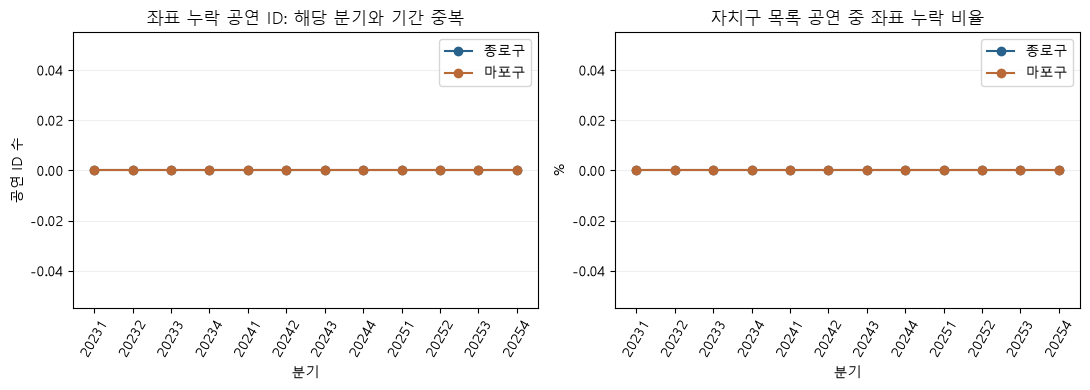

In [15]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
font_names = {f.name for f in fm.fontManager.ttflist}
plt.rcParams['font.family'] = next((n for n in ['Malgun Gothic', 'NanumGothic', 'AppleGothic'] if n in font_names), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for district, color in zip(TARGETS, ['#28618b', '#b96935']):
    data = missing_quarter.loc[missing_quarter['district'].eq(district)]
    axes[0].plot(data['quarter'], data['missing_coordinate_performances'], marker='o', label=district, color=color)
    axes[1].plot(data['quarter'], data['missing_pct'], marker='o', label=district, color=color)
for ax in axes:
    ax.tick_params(axis='x', rotation=60)
    ax.grid(axis='y', alpha=.2)
    ax.legend()
axes[0].set(title='좌표 누락 공연 ID: 해당 분기와 기간 중복', ylabel='공연 ID 수', xlabel='분기')
axes[1].set(title='자치구 목록 공연 중 좌표 누락 비율', ylabel='%', xlabel='분기')
fig.tight_layout()
fig.savefig(FIGURES / '04_missing_coordinates_by_quarter.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

**해석:** 누락이 0건이면 현재 좌표에 의한 누락만 해소된 것이다. 과거 위치와 공연 모집단의 완전성은 별도로 남는다. 누락 규모가 분기별로 다르면 고정된 자치구 차이만으로 설명되지 않는 노출 측정오차가 생긴다. 현재 자료로 오차 방향이나 계수 편향의 크기는 단정할 수 없다. 실제 공연 회차·관객 규모를 확인하지 않은 상태에서 공연 ID 누락 비율을 경제 효과 누락 비율로 바꾸지 않는다.

## 6. 원본의 시간 범위와 이름·기간 수정 흔적

로컬에 보관된 공연 월별 XML의 페이지·행·공연 ID를 직접 센다. 매출·점포 원본에서는 분기 열만 읽는다. 36개 월과 12개 분기가 존재하는 것은 기간 범위 확인이며, API의 전체 모집단이나 과거 시점의 완전한 스냅샷을 보증하지 않는다. 온라인 요청은 하지 않는다.

In [16]:
raw_month_rows, raw_records = [], []
for folder in sorted({path.parent for path in raw_xml}):
    records, pages = [], sorted(path for path in raw_xml if path.parent == folder)
    for path in pages:
        for item in ET.parse(path).getroot().findall('.//db'):
            record = {name: item.findtext(name) for name in ['mt20id', 'prfpdfrom', 'prfpdto', 'fcltynm']}
            record['query_month'] = folder.name
            records.append(record)
    raw_records.extend(records)
    raw_month_rows.append({'month': folder.name, 'xml_pages': len(pages), 'raw_rows': len(records),
                          'unique_performance_ids': len({r['mt20id'] for r in records})})
raw_months = pd.DataFrame(raw_month_rows)
raw_performances = pd.DataFrame(raw_records)
expected_months = {f'{y}{m:02d}' for y in range(2023, 2026) for m in range(1, 13)}
check('missing_raw_performance_month', len(expected_months - set(raw_months['month'])))
check('unexpected_raw_performance_month', len(set(raw_months['month']) - expected_months))
raw_months.to_csv(REPORTS / '04_raw_month_coverage.csv', index=False, encoding='utf-8-sig')
raw_pairs = set(map(tuple, raw_performances[['mt20id', 'query_month']].astype(str).to_numpy()))
processed_pairs = set(map(tuple, month_obs[['mt20id', 'query_month']].astype(str).to_numpy()))
check('raw_processed_month_id_pair_disagreement', len(raw_pairs.symmetric_difference(processed_pairs)))
display(raw_months.groupby(raw_months['month'].str[:4]).agg(
    months=('month', 'size'), xml_pages=('xml_pages', 'sum'), raw_rows=('raw_rows', 'sum')))
print('원본 XML의 고유 공연 ID:', raw_performances['mt20id'].nunique())

,months,xml_pages,raw_rows
month,,,
2023,12,117,11295
2024,12,126,11940
2025,12,140,13324


원본 XML의 고유 공연 ID: 30047


In [17]:
seoul_pointer = ROOT / 'metadata/main/seoul_analysis_sources.json'
seoul_sources = {}
assert seoul_pointer.exists()
if seoul_pointer.exists():
    seoul_snapshot = json.loads(seoul_pointer.read_text(encoding='utf-8'))
    assert seoul_snapshot['status'] == 'validated' and seoul_snapshot['validation_passed']
    for item in seoul_snapshot['items']:
        if item['dataset'] in ['sales', 'stores']:
            csvs = [entry for entry in item['extracted'] if entry['path'].lower().endswith('.csv')]
            assert len(csvs) == 1
            entry = csvs[0]
            assert sha256(ROOT / entry['path']) == entry['sha256']
            seoul_sources[(item['dataset'], int(item['year']))] = ROOT / entry['path']
source_quarter_rows = []
for kind in ['sales', 'stores']:
    for year in range(2023, 2026):
        path = seoul_sources[(kind, year)]
        if path not in watched_paths:
            watched_paths.append(path)
            before_hashes[str(path.relative_to(ROOT))] = sha256(path)
        columns = pd.read_csv(path, encoding='cp949', nrows=0).columns
        qcol = '기준_년분기_코드' if '기준_년분기_코드' in columns else 'stdr_yyqu_cd'
        values = pd.read_csv(path, encoding='cp949', usecols=[qcol], dtype=str)[qcol]
        found = set(values.dropna())
        check(f'raw_{kind}_{year}_quarter_coverage', len(found.symmetric_difference({f'{year}{q}' for q in range(1, 5)})))
        for quarter, rows in values.value_counts().sort_index().items():
            source_quarter_rows.append({'dataset': kind, 'file_year': year, 'quarter': quarter, 'raw_rows': rows})
source_quarters = pd.DataFrame(source_quarter_rows)
source_quarters.to_csv(REPORTS / '04_raw_quarter_coverage.csv', index=False, encoding='utf-8-sig')
display(source_quarters.groupby(['dataset', 'file_year']).agg(quarters=('quarter', 'nunique'), rows=('raw_rows', 'sum')))

quarters    rows
dataset file_year                  
sales   2023              4   88246
        2024              4   87179
        2025              4   85732
stores  2023              4  307741
        2024              4  306889
        2025              4  304775

In [18]:
variants = raw_performances.groupby('mt20id').agg(
    start_variants=('prfpdfrom', 'nunique'), end_variants=('prfpdto', 'nunique'),
    facility_name_variants=('fcltynm', 'nunique'), observed_months=('query_month', 'nunique'))
variant_warnings = variants.loc[variants[['start_variants', 'end_variants', 'facility_name_variants']].gt(1).any(axis=1)].reset_index()
variant_warnings = variant_warnings.merge(linkage[['mt20id', 'fcltynm', 'gugunnm']], on='mt20id', how='left')
variant_warnings.to_csv(REPORTS / '04_raw_record_variants.csv', index=False, encoding='utf-8-sig')
all_ids = set(raw_performances['mt20id'].dropna())
check('raw_unique_ids_disagree_with_linkage', len(all_ids.symmetric_difference(set(linkage['mt20id']))))
print('같은 공연 ID의 월별 시작일·종료일·시설명 변형:', len(variant_warnings))
display(variant_warnings.head(12))
display(Markdown('**해석:** 변형이 0건이어도 현재 저장된 목록 안에서 값이 같다는 의미다. '
                '나중에 갱신된 종료일·시설 정보가 과거 분기에 소급 적용됐을 가능성, 공연 기간 내 휴연, '
                '폐관·이전 시점은 별도 이력 없이 검증할 수 없다. 월별 조회 횟수를 실제 공연 횟수로 세지 않는다.'))

같은 공연 ID의 월별 시작일·종료일·시설명 변형: 0


,mt20id,start_variants,end_variants,facility_name_variants,observed_months,fcltynm,gugunnm


**해석:** 변형이 0건이어도 현재 저장된 목록 안에서 값이 같다는 의미다. 나중에 갱신된 종료일·시설 정보가 과거 분기에 소급 적용됐을 가능성, 공연 기간 내 휴연, 폐관·이전 시점은 별도 이력 없이 검증할 수 없다. 월별 조회 횟수를 실제 공연 횟수로 세지 않는다.

## 7. 연결 검증용 두 업종의 관측 표본

매출과 점포 수의 비음수·관측 조건과 상권당 2개 이상 분기 조건을 적용한 행 수만 확인한다. 여기서 회귀를 추정하지 않는다. 최종 10종 분석의 전체·공통표본은 05~06에서 별도로 제시한다.

In [19]:
sample_rows = []
for industry, group in panel.groupby('industry', observed=True):
    observed = group['total_sales'].notna()
    eligible = (group['total_sales'].ge(0) & group['total_store_count'].ge(0)
                & ~group['negative_sales_flag'] & ~group['negative_store_flag'])
    usable = group.loc[eligible].copy()
    usable = usable.loc[usable.groupby('area_id')['quarter'].transform('nunique').ge(2)]
    sample_rows.append({'industry': industry, 'panel_rows': len(group), 'observed_sales': observed.sum(),
        'missing_sales': (~observed).sum(), 'before_singleton_filter': eligible.sum(),
        'base_model_rows': len(usable), 'area_clusters': usable['area_id'].nunique(),
        'known_zero_500m_model_rows': usable[EXPOSURES[1]].eq(0).sum()})
sample_flow = pd.DataFrame(sample_rows)
sample_flow.to_csv(REPORTS / '04_base_model_sample_flow.csv', index=False, encoding='utf-8-sig')
display(sample_flow)

,industry,panel_rows,observed_sales,missing_sales,before_singleton_filter,base_model_rows,area_clusters,known_zero_500m_model_rows
0,커피-음료,1812,1308,504,1308,1307,115,184
1,한식음식점,1812,1489,323,1489,1488,126,272


**해석과 보완 순서**

1. 좌표 누락 시설이 있으면 공식 상세와 좌표를 확보하고, 누락이 0건이어도 2023~2025년 당시 위치·이전·폐관 이력을 별도로 검증한다. 이 노트북에서는 좌표를 추정하지 않으며 차단된 API를 재시도하지 않는다.
2. 상세 수집 후보의 완료 여부와 전체 목록에 남은 이름 임시 연결을 구분한다. 잔여 이름 연결의 공식 ID 검증과 후보 선정 범위의 대표성을 확인하며, 공식 상세 부분집합의 일치율을 전체의 정확도로 일반화하지 않는다.
3. 결측 매출이 적은 균형 표본, 점포수 통제, 반경별 정의, 기간별·지역별 결과를 비교해 결론의 민감도를 보고한다. 균형 표본도 선택 편향을 제거하지는 않는다.
4. 현재 경계로 과거 분기를 해석한다는 점, 폴리곤까지의 직선거리라는 점을 모든 결과에 함께 명시한다. 과거 경계와 시설 이전 이력은 현재 로컬 자료만으로 복원하지 않는다.
5. 공간 노출은 공식·임시 연결 및 현재 좌표에 기초한 공연 ID 수다. 현재 좌표 확보와 과거 위치 검증은 별개다. 인과효과·공연 회차·관객 수·일별 효과로 확대 해석하지 않는다.

## 8. 감사 결과 저장과 무결성 확인

구조 오류와 해석 한계를 구분한다. 구조 검증이 통과해도 위의 자료 한계는 남는다. 마지막 셀은 필수 검사가 모두 통과했는지 확인하며, 경고는 요약 JSON에 별도로 저장한다.

In [20]:
manifest = pd.DataFrame([{'path': str(p.relative_to(ROOT)), 'sha256_before': before_hashes[str(p.relative_to(ROOT))],
                          'sha256_after': sha256(p)} for p in watched_paths])
manifest['unchanged'] = manifest['sha256_before'].eq(manifest['sha256_after'])
manifest.to_csv(REPORTS / '04_input_integrity.csv', index=False, encoding='utf-8-sig')
check('watched_input_changed', (~manifest['unchanged']).sum(), '선택 원본과 분석 입력의 실행 전후 SHA-256')
check_results = pd.DataFrame(checks)
check_results.to_csv(REPORTS / '04_validation_checks.csv', index=False, encoding='utf-8-sig')
summary = {
    'collection_run_id': linkage_source.get('collection_run_id'),
    'facility_detail_source': source_by_role['facility_details'],
    'performance_detail_source': source_by_role['performance_details'],
    'panel_rows': len(panel), 'areas': panel['area_id'].nunique(), 'quarters': panel['quarter'].nunique(),
    'observed_sales_rows': int(panel['total_sales'].notna().sum()), 'missing_sales_rows': int(absent.sum()),
    'performance_ids': len(linkage), 'official_link_ids': int(official.sum()),
    'official_link_share_pct': float(official.mean() * 100),
    'provisional_name_link_ids': int(linkage['link_method'].isin(['exact_unique_name', 'prefix_unique_name']).sum()),
    'performance_candidate_ids': len(candidate_ids), 'performance_candidate_pending': candidate_pending,
    'name_official_conflict_ids': int(linkage['name_official_conflict'].sum()),
    'list_detail_period_difference_ids': int(period_audit['period_differs'].sum()),
    'list_detail_quarter_membership_difference_ids': int(period_audit['quarter_membership_differs'].sum()),
    'performance_ids_with_coordinates': int(expected_coords.sum()),
    'performance_ids_without_coordinates': int((~expected_coords).sum()),
    'target_missing_facilities': len(missing_target_facilities),
    'target_missing_facilities_with_performances': len(missing_target_with_performances), 'target_missing_performance_ids': len(missing_target),
    'top_four_missing_facility_performance_ids': int(top4), 'ambiguous_normalized_facility_names': len(ambiguous_names),
    'raw_record_variant_ids': len(variant_warnings),
    'distance_source_max_absolute_error_m': float(distance_comparison['absolute_error_m'].max()), 'raw_months': len(raw_months),
    'checks_passed': int(check_results['passed'].sum()), 'checks_total': len(check_results),
    'watched_inputs_unchanged': bool(manifest['unchanged'].all()),
    'model_sample_flow': sample_flow.to_dict(orient='records'),
    'limitations': [f"공식 상세 ID {int(official.sum()):,}/{len(linkage):,}개이며 잔여 이름 임시 연결은 별도 검증 대상", ('좌표 누락은 상권별 노출 과소측정 가능' if (~expected_coords).any() else '현재 목록 좌표 누락 0건이나 과거 시설 위치 이력 미검증'),
                   '현재 경계를 과거 모든 분기에 적용', '기간 중복 공연 ID 수이며 회차·관객·일별 효과 아님',
                   '미제공 매출 제외에 따른 선택 편향 가능', '공식 상세 후보 선정 범위의 선택성은 전체 후보 수집 완료와 별개', '분기 기간은 월별 목록 기준이며 최신 상세 기간 차이는 별도 감사'],
    'network_requests': 0,
}
(REPORTS / '04_audit_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(check_results)
assert check_results['passed'].all(), '검증 실패 항목을 확인하세요.'
display(Markdown(f"**검증 완료:** {len(check_results)}개 구조 검사 통과. 선택 원본·분석 입력 {len(manifest)}개가 실행 전후 동일하다. "
                '분석 가능한 표본과 결과 해석의 제약은 앞의 표와 경고를 함께 확인한다.'))

,check,failed_rows,passed,note
0,panel_duplicate_key,0,True,
1,panel_missing_key,0,True,
2,expected_panel_keys_missing,0,True,
3,unexpected_panel_keys,0,True,
4,outside_district_scope,0,True,
...,...,...,...,...
50,raw_stores_2023_quarter_coverage,0,True,
51,raw_stores_2024_quarter_coverage,0,True,
52,raw_stores_2025_quarter_coverage,0,True,
53,raw_unique_ids_disagree_with_linkage,0,True,


**검증 완료:** 55개 구조 검사 통과. 선택 원본·분석 입력 407개가 실행 전후 동일하다. 분석 가능한 표본과 결과 해석의 제약은 앞의 표와 경고를 함께 확인한다.